# QM640 Capstone Interim Report — RQ1 and RQ2
**Transformer DGA fault classification and explainability | Preliminary, reproducible analysis**

**Research questions.** RQ1 compares four baseline machine-learning classifiers for six-category transformer DGA fault classification. RQ2 evaluates global feature importance using permutation importance and SHAP, including internal ranking stability.

**Data:** `QM640_Public_DGA_Fault_Dataset.xlsx` (589 rows), retrieved from the [project GitHub repository](https://github.com/irurama2018-coder/M640-Transformer-AI-Capstone/blob/main/QM640_Public_DGA_Fault_Dataset.xlsx). The project repository is **not verified as the original dataset publisher**. Confirm original source, licensing, DGA concentration units, and fault-label derivation before final academic citation.

**Important scope:** All results below are exploratory. The dataset lacks verified transformer IDs and sampling dates; a random stratified split cannot demonstrate performance on unseen transformers. No utility maintenance, energy-loss, or CAPEX outcomes are established here.

## 1. Data loading and quality assessment
Run the notebook top-to-bottom in Google Colab. The public dataset must remain accessible at the URL below.

In [1]:
import pandas as pd

dataset_url = (
    "https://raw.githubusercontent.com/"
    "irurama2018-coder/M640-Transformer-AI-Capstone/"
    "main/QM640_Public_DGA_Fault_Dataset.xlsx"
)

df = pd.read_excel(dataset_url)

print("Dataset shape:", df.shape)
print(df.columns.tolist())
print("\nFirst five records:")
display(df.head())
print("\nMissing values by column:")
print(df.isnull().sum())
print("\nExact duplicate rows:", df.duplicated().sum())


Dataset shape: (589, 6)
['H2', 'CH4', 'C2H6', 'C2H4', 'C2H2', '故障类型']

First five records:


,H2,CH4,C2H6,C2H4,C2H2,故障类型
0,1458.0,9.0,1812.0000,0.0001,0.0001,PD
1,2240.0,157.0,90.0000,157.0000,45.0000,PD
2,73.0,8.0,4.0000,2.0000,12.0000,PD
3,235.0,16.0,0.0001,35.0000,0.0001,PD
4,9340.0,995.0,60.0000,6.0000,7.0000,PD



Missing values by column:
H2      0
CH4     0
C2H6    0
C2H4    0
C2H2    0
故障类型    0
dtype: int64

Exact duplicate rows: 2


In [2]:
# RQ1 - Step 2: Dataset quality verification

# Verify and print the total number of records
print("Total records:", len(df))

# Display the count and distribution of different transformer fault categories
print("\nFault class distribution:")
print(df["故障类型"].value_counts())

# Re-verify and print the count of missing values per feature column
print("\nMissing values:")
print(df.isnull().sum())

# Count and display duplicate observations in the data
print("\nDuplicate records:")
print(df.duplicated().sum())

# Check the schema data types of all feature and target columns
print("\nData types:")
print(df.dtypes)

Total records: 589

Fault class distribution:
故障类型
D2    149
T1    111
T3    104
D1     91
PD     74
T2     60
Name: count, dtype: int64

Missing values:
H2      0
CH4     0
C2H6    0
C2H4    0
C2H2    0
故障类型    0
dtype: int64

Duplicate records:
2

Data types:
H2      float64
CH4     float64
C2H6    float64
C2H4    float64
C2H2    float64
故障类型     object
dtype: object


**Quality observations.** There are six fault categories and two exact duplicate rows; the duplicates are retained because distinct sampling events cannot be distinguished without identifiers. No missing cells were found. Review whether values such as `0.0001` represent a measurement, zero substitution, or detection limit. Do not treat this file name as proof of IEEE endorsement.

## 2. RQ1 — Baseline Random Forest classification
The 80:20 stratified split produces 471 training and 118 test observations. This is a **preliminary holdout assessment**, not an external validation. The holdout was also inspected during exploratory model comparison; a fresh independent test set is needed for confirmatory evaluation.

Training records: 471
Testing records: 118

Accuracy: 0.7712
Balanced accuracy: 0.7342

Classification report:
              precision    recall  f1-score   support

          D1       0.62      0.56      0.59        18
          D2       0.76      0.87      0.81        30
          PD       0.86      0.80      0.83        15
          T1       0.80      0.91      0.85        22
          T2       0.71      0.42      0.53        12
          T3       0.82      0.86      0.84        21

    accuracy                           0.77       118
   macro avg       0.76      0.73      0.74       118
weighted avg       0.77      0.77      0.76       118



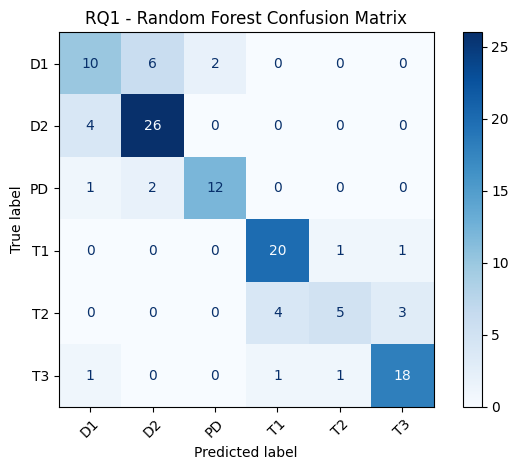

In [3]:
# RQ1 - Step 3: Random Forest Classification

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Specify the five distinct DGA gas features utilized as predictors
features = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]

# Split variables into predictor matrix X and label vector y
X = df[features]
y = df["故障类型"]

# Perform a stratified 80/20 split to maintain class balance in train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Instantiate a Random Forest Classifier with balanced class weights
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Fit the Random Forest model on the stratified training subset
model.fit(X_train, y_train)

# Predict fault classes on the holdout test subset
y_pred = model.predict(X_test)

# Output training and testing subset sample sizes
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Print model performance evaluation metrics (accuracy and balanced accuracy)
print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 4))

# Print a detailed classification report with precision, recall, and F1 scores per fault class
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display the confusion matrix to evaluate class-wise predictions visually
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("RQ1 - Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

### RQ1 model comparison
The four models below are baseline configurations, **not exhaustively tuned**. Comparison on the holdout is exploratory and should not be used as a final unbiased model-selection procedure. For a final analysis, tune/select within training-only cross-validation and assess once on an untouched independent test set.

In [4]:
# RQ1 - Step 4: Compare Four ML Algorithms

import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Initialize four baseline classifiers for comparison using pipelines where scaling is required
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

results = []

# Iterate, train, and capture testing metrics for each classifier
for name, clf in models.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

# Consolidate results into a DataFrame and sort by the primary evaluation metric (Macro F1)
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    "Macro F1", ascending=False
)

# Display comparison metrics rounded to 4 decimal places
display(comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
1,Random Forest,0.7712,0.7342,0.7405
3,Gradient Boosting,0.7203,0.6918,0.6965
0,Logistic Regression,0.5000,0.4007,0.3444
2,SVM,0.2542,0.2358,0.1791


### Training-only five-fold cross-validation
These folds overlap in training observations; the standard deviation describes variation between folds and is not a confidence interval for new transformers.

In [5]:
# RQ1 - Step 5: Random Forest Cross-Validation
# Use only the training data, preserving the test set for internal validation; this does not establish independent equipment-level generalization.

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.ensemble import RandomForestClassifier

# Define the stratified 5-fold cross-validation split strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Instantiate the Random Forest model for validation
rf_cv = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Evaluate the model across multiple key metrics on the cross-validation folds
scores = cross_validate(
    rf_cv,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1
)

# Organise the fold scores into a display DataFrame
results_cv = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": scores["test_accuracy"],
    "Balanced Accuracy": scores["test_balanced_accuracy"],
    "Macro F1": scores["test_macro_f1"]
})

# Output fold results
display(results_cv.round(4))

# Calculate and print the mean and standard deviation for each metric
print("\nCross-validation summary:")
for metric in ["Accuracy", "Balanced Accuracy", "Macro F1"]:
    print(
        f"{metric}: "
        f"{results_cv[metric].mean():.4f} "
        f"+/- {results_cv[metric].std():.4f}"
    )

,Fold,Accuracy,Balanced Accuracy,Macro F1
0,1,0.8421,0.8187,0.8313
1,2,0.7979,0.7616,0.7776
2,3,0.7447,0.6963,0.7092
3,4,0.7766,0.7528,0.7558
4,5,0.7979,0.7762,0.7918



Cross-validation summary:
Accuracy: 0.7918 +/- 0.0356
Balanced Accuracy: 0.7611 +/- 0.0442
Macro F1: 0.7731 +/- 0.0451


### RQ1 interpretation
The saved holdout Random Forest accuracy was **0.7712**, balanced accuracy **0.7342**, and macro-F1 **0.7405**. Training-only five-fold cross-validation mean macro-F1 was **0.7731** (SD **0.0451**). **T2 recall was 0.42** (12 test cases) and **D1 recall was 0.56** (18 test cases). These are important limitations for safety-related use. Results do not demonstrate absence of overfitting, validated transformer-level generalization, or operational readiness.

## 3. RQ2 — Permutation importance and SHAP
Permutation importance measures the reduction in macro-F1 after a feature is shuffled; SHAP measures model attribution. The two scores have different scales and should **not** be plotted on a single common quantitative axis.

,DGA Gas,Mean Importance,Standard Deviation
4,C2H2,0.3261,0.0428
3,C2H4,0.3059,0.0351
0,H2,0.1829,0.0306
2,C2H6,0.1107,0.0353
1,CH4,0.0549,0.0282


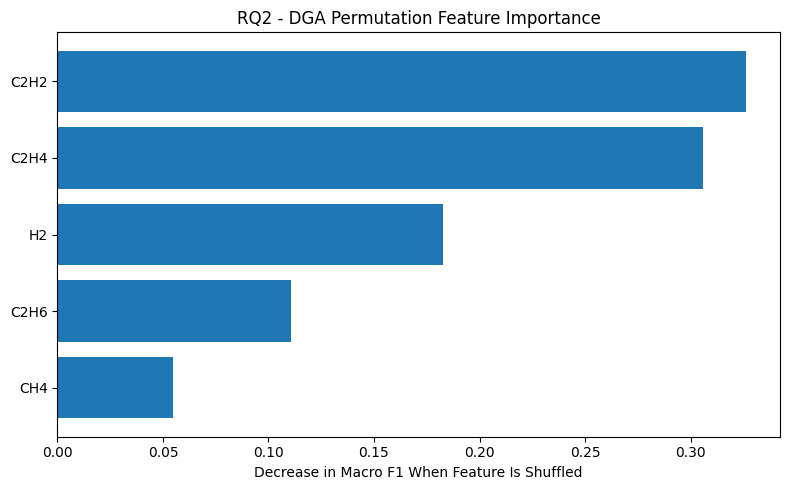

In [6]:
# RQ2 - Step 1: Permutation Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Compute permutation importance values using the trained Random Forest model on the already-inspected holdout set (exploratory)
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# Aggregate mean and standard deviation of importance scores into a sorted DataFrame
importance_df = pd.DataFrame({
    "DGA Gas": X_test.columns,
    "Mean Importance": importance.importances_mean,
    "Standard Deviation": importance.importances_std
}).sort_values("Mean Importance", ascending=False)

# Print the importance levels
display(importance_df.round(4))

# Plot the horizontal bar chart showing permutation feature importance levels for each DGA gas
plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["DGA Gas"],
    importance_df["Mean Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Decrease in Macro F1 When Feature Is Shuffled")
plt.title("RQ2 - DGA Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [7]:
# RQ2 - Step 2: Complete DGA feature importance

# Display all 5 DGA gas importance scores in a clear tabular format
print("All five DGA gas importance values:")
display(importance_df.to_string(index=False))

# Print count to confirm all 5 gases are processed
print("\nNumber of gases:", len(importance_df))

# Export the permutation importance results to a CSV file for reporting
importance_df.to_csv(
    "RQ2_DGA_Permutation_Importance.csv",
    index=False
)

All five DGA gas importance values:


'DGA Gas  Mean Importance  Standard Deviation\n   C2H2         0.326102            0.042762\n   C2H4         0.305851            0.035088\n     H2         0.182875            0.030551\n   C2H6         0.110671            0.035305\n    CH4         0.054867            0.028238'


Number of gases: 5


SHAP values shape: (50, 5, 6)
Model classes: ['D1' 'D2' 'PD' 'T1' 'T2' 'T3']


,DGA Gas,Mean Absolute SHAP
4,C2H2,0.10608
3,C2H4,0.07982
0,H2,0.05696
2,C2H6,0.04083
1,CH4,0.02852


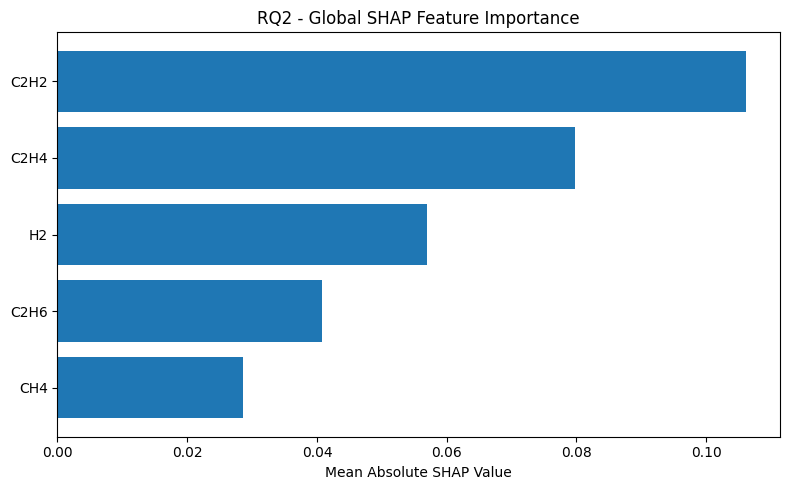

In [8]:
# RQ2 - Step 3: SHAP for multiclass Random Forest

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Construct a tree SHAP explainer on the trained Random Forest model
explainer = shap.TreeExplainer(model)

# Extract a manageable sample size (first 50 test rows) for SHAP explanation
X_explain = X_test.iloc[:50].copy()
shap_values = explainer.shap_values(X_explain)

# Reshape SHAP array outputs to maintain standard formatting: (samples, features, classes)
if isinstance(shap_values, list):
    values = np.stack(shap_values, axis=-1)
else:
    values = np.asarray(shap_values)

# Print dimensions and class list attributes of computed SHAP outputs
print("SHAP values shape:", values.shape)
print("Model classes:", model.classes_)

# Calculate overall global feature importance as the mean absolute SHAP value
overall_importance = np.abs(values).mean(axis=(0, 2))

# Structure calculated SHAP importance into a sorted pandas DataFrame
shap_importance = pd.DataFrame({
    "DGA Gas": X_explain.columns,
    "Mean Absolute SHAP": overall_importance
}).sort_values("Mean Absolute SHAP", ascending=False)

# Display the SHAP importance table
display(shap_importance.round(5))

# Plot the global mean absolute SHAP values per feature
plt.figure(figsize=(8, 5))
plt.barh(
    shap_importance["DGA Gas"],
    shap_importance["Mean Absolute SHAP"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mean Absolute SHAP Value")
plt.title("RQ2 - Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

### SHAP global ranking stability across retrained models
Five Random Forest fits use overlapping subsets of the **training** data and a common 50-observation explanation sample drawn from the already-explored holdout. This measures internal global **ranking stability**, not independent external replication, stability of individual explanations, or prediction accuracy.

In [9]:
# RQ2 - Step 4: SHAP Explanation Stability
# Uses cross-validation folds on the training dataset to examine internal ranking stability on a fixed, already-inspected sample.

import numpy as np
import pandas as pd
import shap

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import spearmanr
from itertools import combinations

# Define the gas features
features = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]

# Setup the same stratified 5-fold splits as step 5
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rankings = []

# Perform iterative cross-validation to gather fold-specific SHAP scores
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    # Fit a new classifier model on this training fold split
    rf = RandomForestClassifier(
        n_estimators=200,
        random_state=42 + fold,
        class_weight="balanced"
    )
    rf.fit(X_fold_train, y_fold_train)

    # Generate SHAP value explanations for the fixed test observations
    explainer = shap.TreeExplainer(rf)
    values = explainer.shap_values(X_test.iloc[:50])

    if isinstance(values, list):
        values = np.stack(values, axis=-1)
    else:
        values = np.asarray(values)

    # Calculate feature scores for this fold and append
    mean_abs = np.abs(values).mean(axis=(0, 2))
    rankings.append(mean_abs)

rankings = np.array(rankings)

# Display importance scores recorded across each fold
stability_df = pd.DataFrame(
    rankings,
    columns=features,
    index=[f"Fold {i}" for i in range(1, 6)]
)

display(stability_df.round(5))

spearman_scores = []
jaccard_scores = []

# Calculate pairwise similarity (Spearman rho and Jaccard) between fold metrics to evaluate consistency
for i, j in combinations(range(5), 2):
    rho, _ = spearmanr(rankings[i], rankings[j])
    spearman_scores.append(rho)

    top_i = set(np.argsort(rankings[i])[-3:])
    top_j = set(np.argsort(rankings[j])[-3:])

    jaccard = len(top_i & top_j) / len(top_i | top_j)
    jaccard_scores.append(jaccard)

# Print metrics evaluating the SHAP model's feature rank stability
print("Mean Spearman correlation:",
      round(np.mean(spearman_scores), 4))

print("Mean top-3 Jaccard similarity:",
      round(np.mean(jaccard_scores), 4))

,H2,CH4,C2H6,C2H4,C2H2
Fold 1,0.05206,0.02668,0.04327,0.08085,0.10436
Fold 2,0.05529,0.02868,0.03841,0.07886,0.11021
Fold 3,0.05810,0.02742,0.04035,0.08076,0.10380
Fold 4,0.05187,0.02678,0.04042,0.08280,0.10661
Fold 5,0.05694,0.02669,0.03689,0.07772,0.10491


Mean Spearman correlation: 1.0
Mean top-3 Jaccard similarity: 1.0


In [10]:
# RQ2: compare rankings, not incompatible metric magnitudes
perm = importance_df[['DGA Gas', 'Mean Importance']].copy()
perm['Permutation Rank'] = perm['Mean Importance'].rank(ascending=False, method='min').astype(int)
shap_r = shap_importance[['DGA Gas', 'Mean Absolute SHAP']].copy()
shap_r['SHAP Rank'] = shap_r['Mean Absolute SHAP'].rank(ascending=False, method='min').astype(int)
rank_comparison = perm.merge(shap_r, on='DGA Gas').sort_values('Permutation Rank')
display(rank_comparison.round(5))


,DGA Gas,Mean Importance,Permutation Rank,Mean Absolute SHAP,SHAP Rank
0,C2H2,0.32610,1,0.10608,1
1,C2H4,0.30585,2,0.07982,2
2,H2,0.18287,3,0.05696,3
3,C2H6,0.11067,4,0.04083,4
4,CH4,0.05487,5,0.02852,5


## 4. Consolidated preliminary findings

**RQ1.** Four baseline supervised models were compared on a 589-record, six-class DGA dataset (471 training; 118 holdout). Random Forest performed best in this *exploratory* comparison (accuracy 0.7712; balanced accuracy 0.7342; macro-F1 0.7405). Training-only five-fold CV yielded mean macro-F1 0.7731 (SD 0.0451). Low T2 recall (0.42) and D1 recall (0.56) require further investigation.

**RQ2.** Both permutation importance and global SHAP ranked the gases **C₂H₂ > C₂H₄ > H₂ > C₂H₆ > CH₄**. Across five retrained Random Forest models, mean pairwise Spearman rank correlation and top-three Jaccard similarity were both **1.0000**. This means the global ordering was identical under the tested retraining setup, **not** that the model is 100% reliable.

**Limits and responsible use.** The original dataset provenance, gas units, fault-label quality, transformer identity, and sampling independence require verification. A random split can overestimate deployment performance if related records occur in both partitions. The holdout was consulted for exploratory comparisons and explanation analysis, so these results must not be presented as final independent validation. Global importance is not causal evidence, nor does it establish class-specific physical fault mechanisms. AI recommendations must remain subject to qualified engineering review. No measured maintenance savings, transformer energy-loss reductions, or CAPEX improvements are claimed from these DGA data.

